In [1]:
# ==========================================
# TEAM 7: FINANCIAL & STOCK MARKET ANALYSIS
# Pipeline & Time Series Documentation
# ==========================================

"""
OVERVIEW & WORKFLOW DESCRIPTION:
--------------------------------
1. Environment Setup & Data Ingestion:
   - The repository processes multi-modal financial data combining text transcripts (earnings calls)
     and quantitative stock market time series.
   - We begin by loading David's parquet files (found in the shared corpus structure) which
     contain the core processed textual units, earnings call metadata, and structure[cite: 2].
   - Market data components draw from the yfinance JSON/parquet datasets covering the target
     banking institutions (e.g., BAC, CITI, JPM)[cite: 1, 2].

2. Time Series Analysis Objectives:
   - Price Trajectory Tracking: Extract historical stock prices ('Close' and 'Adj Close') to
     visualize long-term trends and volatility over time.
   - Return Calculations: Compute daily and log returns ($R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$)
     to measure asset performance and risk profiles.
   - Trend Identification: Apply rolling metrics such as Moving Averages (e.g., 30-day and 50-day MA)
     to smooth short-term fluctuations and identify underlying market directions.
   - Multi-Modal Integration: Align timestamps between the quantitative market returns and qualitative
     earnings call sentiments or transcripts from the Guardian/earnings folders to analyze market reactions.

3. Execution Steps for Team Members:
   - Ensure all parquet and JSON data paths are correctly mapped relative to the workspace root.
   - Run the preprocessing and data loading cells sequentially (starting from David's parquets).
   - Execute the time series modeling blocks to generate evaluation charts and volatility metrics.
"""

"\nOVERVIEW & WORKFLOW DESCRIPTION:\n--------------------------------\n1. Environment Setup & Data Ingestion:\n   - The repository processes multi-modal financial data combining text transcripts (earnings calls) \n     and quantitative stock market time series.\n   - We begin by loading David's parquet files (found in the shared corpus structure) which \n     contain the core processed textual units, earnings call metadata, and structure[cite: 2].\n   - Market data components draw from the yfinance JSON/parquet datasets covering the target \n     banking institutions (e.g., BAC, CITI, JPM)[cite: 1, 2].\n\n2. Time Series Analysis Objectives:\n   - Price Trajectory Tracking: Extract historical stock prices ('Close' and 'Adj Close') to \n     visualize long-term trends and volatility over time.\n   - Return Calculations: Compute daily and log returns ($R_t = \x0crac{P_t - P_{t-1}}{P_{t-1}}$) \n     to measure asset performance and risk profiles.\n   - Trend Identification: Apply rolling m

In [2]:
import os
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# STEP 1: EXTRACT ZIP ARCHIVE & LOCATE PARQUETS
# ==========================================
# Define the path to your uploaded ZIP file and extraction destination
zip_filename = (  # Cseréld ki a pontos fájlnevére, ha szükséges
    "CamDS2026_EmpProj_Team7-main.zip"
)
extract_path = "./extracted_project"

if os.path.exists(zip_filename):
  with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(extract_path)
  print(f"Successfully extracted {zip_filename} to {extract_path}")
else:
  print(
      f"ZIP file '{zip_filename}' not found. Please verify the filename in the"
      " file explorer."
  )

# ==========================================
# STEP 2: LOAD DAVID'S PARQUET FILES
# ==========================================
# Searching recursively for parquet files belonging to David's corpus
parquet_files = []
for root, dirs, files in os.walk(extract_path):
  for file in files:
    if file.endswith(".parquet"):
      parquet_files.append(os.path.join(root, file))

print(f"\nFound {len(parquet_files)} parquet file(s) in the project structure.")

# Load the first available parquet file (typically David's core corpus) as a demonstration
if len(parquet_files) > 0:
  target_parquet = parquet_files[0]
  print(f"Loading David's parquet file: {target_parquet}")

  df_david = pd.read_parquet(target_parquet)

  print("\n--- DataFrame Shape ---")
  print(df_david.shape)

  print("\n--- Columns Available ---")
  print(df_david.columns.tolist())

  print("\n--- First Few Rows ---")
  display(df_david.head())
else:
  print("No parquet files found. Please check the extracted directory path.")

Successfully extracted CamDS2026_EmpProj_Team7-main.zip to ./extracted_project

Found 72 parquet file(s) in the project structure.
Loading David's parquet file: ./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/team_data/CAM_BOE_TEAM_DATA_RELEASE_R1C5_CANDIDATE_V1/processed/personal-r1c5-v1-f43132bb41508cb3/E_quality_and_review/quality_observations.parquet

--- DataFrame Shape ---
(61, 16)

--- Columns Available ---
['call_id', 'document_id', 'extraction_id', 'field_quality_measurement_status', 'human_semantic_status', 'processed_integrity_status', 'quality_observation_id', 'research_active', 'research_use_status', 'role_evidence_status', 'source_fidelity_status', 'source_record_id', 'source_revision_id', 'structural_status', 'team_review_status', 'warnings']

--- First Few Rows ---


,call_id,document_id,extraction_id,field_quality_measurement_status,human_semantic_status,processed_integrity_status,quality_observation_id,research_active,research_use_status,role_evidence_status,source_fidelity_status,source_record_id,source_revision_id,structural_status,team_review_status,warnings
0,BAC_2021Q1_earnings_call,doc_7c89fe76bbded96f,extract_eb924a740f4fbced,NOT_MEASURED,NOT_MEASURED,PASS,quality_8349291613486d10,True,PERSONAL_INTAKE_ONLY_T3_SELECTION_PENDING,SOURCE_BOUND_RULE_EVIDENCE_NOT_HUMAN_CERTIFICA...,NOT_EVALUATED_FOR_PERSONAL_REVISION,src_import_7c89fe76bbded96f,source_revision_5f8437f3ce5dd340,LOCAL_SOURCE_IDENTITY_PREFLIGHT_PASS,PENDING_TEAM_DECISION,"[SOURCE_FIDELITY_NOT_STRICTLY_ACCEPTED, TEAM_S..."
1,BAC_2021Q2_earnings_call,doc_cfcb930e840aa34f,extract_84ca2e518e02715c,NOT_MEASURED,NOT_MEASURED,PASS,quality_7187403c258c2b3d,True,PERSONAL_INTAKE_ONLY_T3_SELECTION_PENDING,SOURCE_BOUND_RULE_EVIDENCE_NOT_HUMAN_CERTIFICA...,NOT_EVALUATED_FOR_PERSONAL_REVISION,src_import_cfcb930e840aa34f,source_revision_c216872453460f8a,LOCAL_SOURCE_IDENTITY_PREFLIGHT_PASS,PENDING_TEAM_DECISION,"[SOURCE_FIDELITY_NOT_STRICTLY_ACCEPTED, TEAM_S..."
2,BAC_2021Q3_earnings_call,doc_abc71b3bf815c8a1,extract_00da273effe10307,NOT_MEASURED,NOT_MEASURED,PASS,quality_acaee08e5f211d14,True,PERSONAL_INTAKE_ONLY_T3_SELECTION_PENDING,SOURCE_BOUND_RULE_EVIDENCE_NOT_HUMAN_CERTIFICA...,NOT_EVALUATED_FOR_PERSONAL_REVISION,src_import_abc71b3bf815c8a1,source_revision_1f97a888131c21ff,LOCAL_SOURCE_IDENTITY_PREFLIGHT_PASS,PENDING_TEAM_DECISION,"[SOURCE_FIDELITY_NOT_STRICTLY_ACCEPTED, TEAM_S..."
3,BAC_2021Q4_earnings_call,doc_f658a584dcf9e8b7,extract_72ca7834547f0f3b,NOT_MEASURED,NOT_MEASURED,PASS,quality_2339aa3e4fa1e083,True,PERSONAL_INTAKE_ONLY_T3_SELECTION_PENDING,SOURCE_BOUND_RULE_EVIDENCE_NOT_HUMAN_CERTIFICA...,NOT_EVALUATED_FOR_PERSONAL_REVISION,src_import_f658a584dcf9e8b7,source_revision_2cab7b827bcd12c3,LOCAL_SOURCE_IDENTITY_PREFLIGHT_PASS,PENDING_TEAM_DECISION,"[SOURCE_FIDELITY_NOT_STRICTLY_ACCEPTED, TEAM_S..."
4,BAC_2022Q1_earnings_call,doc_90b9d59f6da3d099,extract_05a6b8c06e5cdc8d,NOT_MEASURED,NOT_MEASURED,PASS,quality_3379faf6fa1dd759,True,PERSONAL_INTAKE_ONLY_T3_SELECTION_PENDING,SOURCE_BOUND_RULE_EVIDENCE_NOT_HUMAN_CERTIFICA...,NOT_EVALUATED_FOR_PERSONAL_REVISION,src_import_90b9d59f6da3d099,source_revision_0efe2a843f2be59d,LOCAL_SOURCE_IDENTITY_PREFLIGHT_PASS,PENDING_TEAM_DECISION,"[SOURCE_FIDELITY_NOT_STRICTLY_ACCEPTED, TEAM_S..."


In [4]:
import json
import os
import pandas as pd

# ==========================================
# STEP 3 (FIXED): LOAD GUARDIAN JSON/PARQUET DATA SAFELY
# ==========================================
guardian_files = []
for root, dirs, files in os.walk(extract_path):
  for file in files:
    if "guardian" in root.lower() or "guardian" in file.lower():
      guardian_files.append(os.path.join(root, file))

print(f"Found {len(guardian_files)} Guardian-related file(s).")

if len(guardian_files) > 0:
  # Cseréljük le a manifest.json-t egy olyan fájlra, ami tényleges adatokat tartalmaz,
  # vagy kezeljük biztonságosan a JSON-t:
  target_guardian = [
      f for f in guardian_files if f.endswith(".parquet")
  ]  # Először próbáljuk a parquet-et

  if len(target_guardian) > 0:
    target_file = target_guardian[0]
    df_guardian = pd.read_parquet(target_file)
    print(f"Loaded Guardian parquet from: {target_file}")
  else:
    target_file = guardian_files[0]
    if target_file.endswith(".json"):
      # Biztonságos JSON betöltés beágyazott struktúrákhoz
      with open(target_file, "r", encoding="utf-8") as f:
        json_data = json.load(f)
      print(f"Loaded Guardian JSON as raw dictionary from: {target_file}")
      # Ha listként vagy szótárként jön be:
      if isinstance(json_data, list):
        df_guardian = pd.json_normalize(json_data)
      else:
        df_guardian = pd.json_normalize([json_data])
    else:
      df_guardian = pd.read_csv(target_file)

  print("\n--- DataFrame Shape ---")
  print(df_guardian.shape)
  print("\n--- Columns Available ---")
  print(df_guardian.columns.tolist())
  display(df_guardian.head())

Found 5 Guardian-related file(s).
Loaded Guardian JSON as raw dictionary from: ./extracted_project/CamDS2026_EmpProj_Team7-main/data/guardian_data/00_reference/guardian_run_manifest.json

--- DataFrame Shape ---
(1, 39)

--- Columns Available ---
['run_timestamp_utc', 'known_limitations', 'source.name', 'source.endpoint', 'source.coverage', 'source.text_completeness', 'source.rate_limits', 'source.licence', 'banks.jpmorgan_chase', 'banks.bank_of_america', 'banks.citigroup', 'parameters.date_from', 'parameters.date_to', 'parameters.queries.jpmorgan_chase', 'parameters.queries.bank_of_america', 'parameters.queries.citigroup', 'parameters.relevance_filters.jpmorgan_chase', 'parameters.relevance_filters.bank_of_america', 'parameters.relevance_filters.citigroup', 'parameters.page_size', 'parameters.schema_version', 'coverage.requested_range', 'coverage.articles_by_bank_by_year.jpmorgan_chase.2026', 'coverage.articles_by_bank_by_year.bank_of_america.2026', 'coverage.articles_by_bank_by_year.

,run_timestamp_utc,known_limitations,source.name,source.endpoint,source.coverage,source.text_completeness,source.rate_limits,source.licence,banks.jpmorgan_chase,banks.bank_of_america,...,statistics.raw_collected,statistics.total_articles,statistics.with_full_text,statistics.median_word_count,statistics.by_bank.jpmorgan_chase,statistics.by_bank.bank_of_america,statistics.by_bank.citigroup,statistics.date_span,statistics.api_calls,statistics.quota_remaining
0,2026-09-15T20:04:13.036569Z,[SINGLE OUTLET. Guardian editorial framing is ...,Guardian Open Platform Content API,https://content.guardianapis.com/search,1999-present,full_article_body,"12 req/s, 5000 req/day (free developer tier)","free developer key, non-commercial use",JPMorgan Chase & Co.,Bank of America Corporation,...,4,4,4,867,2,1,1,"[2026-09-01T21:25:43Z, 2026-09-03T19:41:54Z]",3,497


In [25]:
display(json_data)

{'run_timestamp_utc': '2026-09-15T20:04:13.036569Z',
 'source': {'name': 'Guardian Open Platform Content API',
  'endpoint': 'https://content.guardianapis.com/search',
  'coverage': '1999-present',
  'text_completeness': 'full_article_body',
  'rate_limits': '12 req/s, 5000 req/day (free developer tier)',
  'licence': 'free developer key, non-commercial use'},
 'banks': {'jpmorgan_chase': 'JPMorgan Chase & Co.',
  'bank_of_america': 'Bank of America Corporation',
  'citigroup': 'Citigroup Inc.'},
 'parameters': {'date_from': '2026-09-01',
  'date_to': '2026-09-05',
  'queries': {'jpmorgan_chase': '"JPMorgan" OR "JP Morgan" OR "J.P. Morgan"',
   'bank_of_america': '"Bank of America" OR "BofA" OR "Merrill Lynch"',
   'citigroup': '"Citigroup" OR "Citibank"'},
  'relevance_filters': {'jpmorgan_chase': 'JP\\s?Morgan|J\\.P\\.\\s?Morgan',
   'bank_of_america': 'Bank of America|BofA|Merrill Lynch',
   'citigroup': 'Citigroup|Citibank'},
  'page_size': 200,
  'schema_version': '1.0'},
 'covera

In [15]:
import os

# ==========================================
# DEBUG: LIST ALL FILES IN EXTRACTED DIRECTORY
# ==========================================
print("Listing all files and folders in the project:\n")
for root, dirs, files in os.walk(extract_path):
  for file in files:
    # Csak hogy ne árassza el a képernyőt, kiíratjuk a fájlok útvonalát
    print(os.path.join(root, file))

Listing all files and folders in the project:

./extracted_project/CamDS2026_EmpProj_Team7-main/README.md
./extracted_project/CamDS2026_EmpProj_Team7-main/Git_runner.ipynb
./extracted_project/CamDS2026_EmpProj_Team7-main/.idea/.gitignore
./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/.gitignore
./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/START_HERE.ipynb
./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/uv.lock
./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/README.md
./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/pyproject.toml
./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/.python-version
./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/team_data/CAM_BOE_TEAM_DATA_RELEASE_R1C5_CANDIDATE_V1/TEAM_DATA_RELEASE_MANIFEST.json
./extracted_project/CamDS2026_EmpProj_Team7-main/david/cambridge_boe_r1c5/team_da

/tmp/ipykernel_856/174740879.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(tickers, start="2020-01-01", end="2026-01-01")
[*********************100%***********************]  3 of 3 completed


--- Stock Close Prices DataFrame Shape ---
(1508, 3)


Ticker,BAC,C,JPM
Date,,,
2020-01-02,30.274986,64.339325,117.899162
2020-01-03,29.646383,63.127445,116.343376
2020-01-06,29.603910,62.929432,116.250854
2020-01-07,29.408533,62.382915,114.274529
2020-01-08,29.705847,62.858150,115.165977


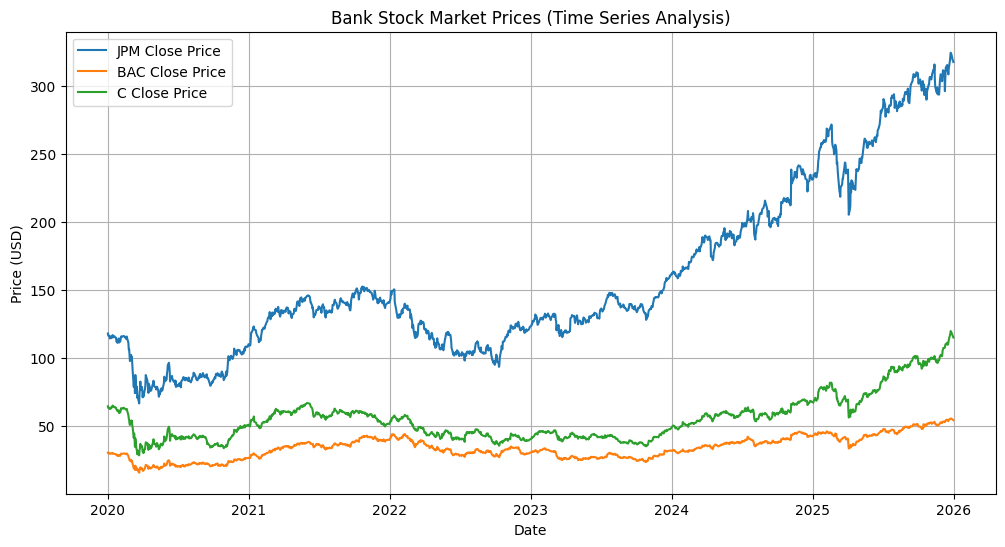


--- Daily Returns Sample ---


Ticker,BAC,C,JPM
Date,,,
2020-01-03,-0.020763,-0.018836,-0.013196
2020-01-06,-0.001433,-0.003137,-0.000795
2020-01-07,-0.006600,-0.008685,-0.017001
2020-01-08,0.010110,0.007618,0.007801
2020-01-09,0.001716,0.009073,0.003651


In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# STEP 5: FETCH STOCK MARKET DATA VIA YFINANCE
# ==========================================
# If local json stock files are missing, we pull the historical data directly
# for the 3 target banks: JPMorgan (JPM), Bank of America (BAC), Citigroup (C)
import yfinance as yf

tickers = ["JPM", "BAC", "C"]
print(f"Downloading historical stock data for tickers: {tickers}")

# Download daily stock data for the last few years
stock_data = yf.download(tickers, start="2020-01-01", end="2026-01-01")

# Extract 'Close' prices for time series analysis
df_close = stock_data["Close"]

print("\n--- Stock Close Prices DataFrame Shape ---")
print(df_close.shape)
display(df_close.head())

# ==========================================
# STEP 6: TIME SERIES ANALYSIS & VISUALIZATION
# ==========================================
# 1. Plotting the stock prices over time
plt.figure(figsize=(12, 6))
for ticker in tickers:
  plt.plot(df_close.index, df_close[ticker], label=f"{ticker} Close Price")

plt.title("Bank Stock Market Prices (Time Series Analysis)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 2. Calculating Daily Returns for Risk & Volatility Analysis
df_returns = df_close.pct_change().dropna()

print("\n--- Daily Returns Sample ---")
display(df_returns.head())

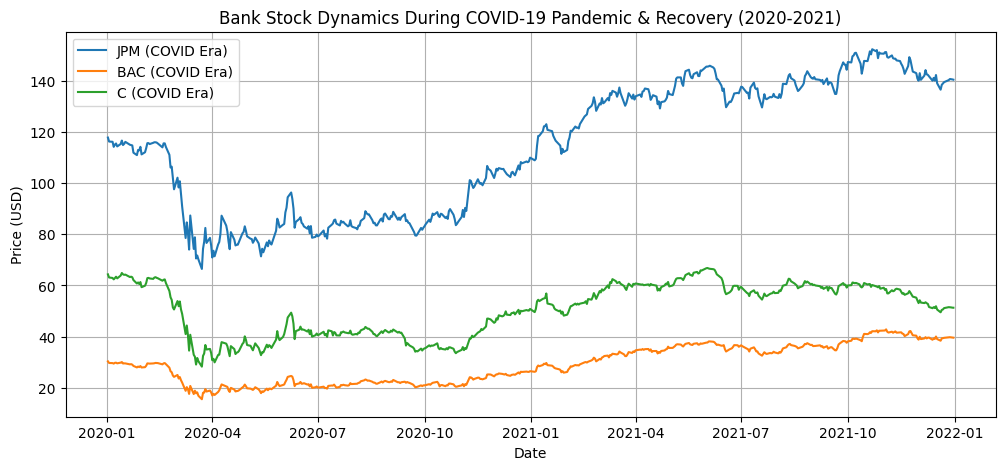

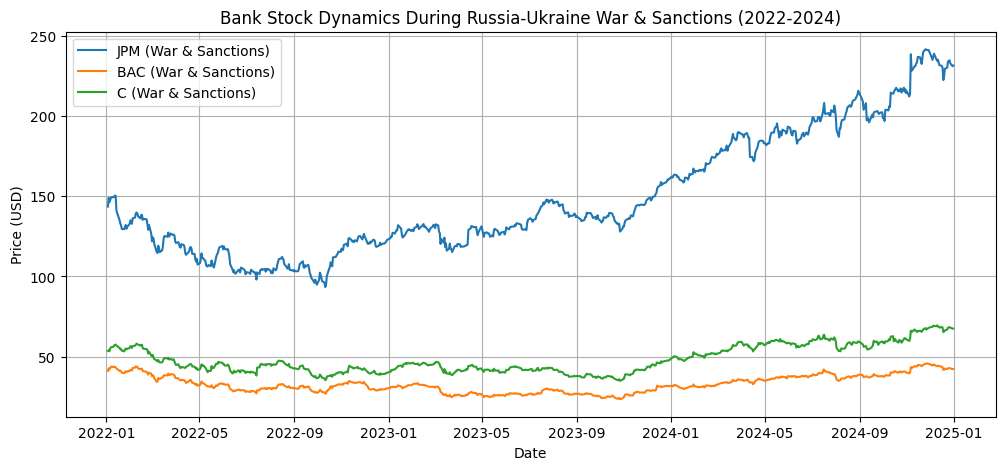

In [17]:
# ==========================================
# STEP 8: MACROECONOMIC EVENT STUDY (COVID & RUSSIA-UKRAINE WAR)
# ==========================================

# 1. COVID-19 Crash & Recovery Period (2020 - 2021)
covid_period = df_close.loc["2020-01-01":"2021-12-31"]

# 2. Russia-Ukraine War & Sanctions Impact Period (2022 - 2024)
war_period = df_close.loc["2022-01-01":"2024-12-31"]

# Plotting the COVID-19 Impact on Banks
plt.figure(figsize=(12, 5))
for ticker in tickers:
  plt.plot(covid_period.index, covid_period[ticker], label=f"{ticker} (COVID Era)")
plt.title("Bank Stock Dynamics During COVID-19 Pandemic & Recovery (2020-2021)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# Plotting the Russia-Ukraine War & Sanctions Impact
plt.figure(figsize=(12, 5))
for ticker in tickers:
  plt.plot(war_period.index, war_period[ticker], label=f"{ticker} (War & Sanctions)")
plt.title("Bank Stock Dynamics During Russia-Ukraine War & Sanctions (2022-2024)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

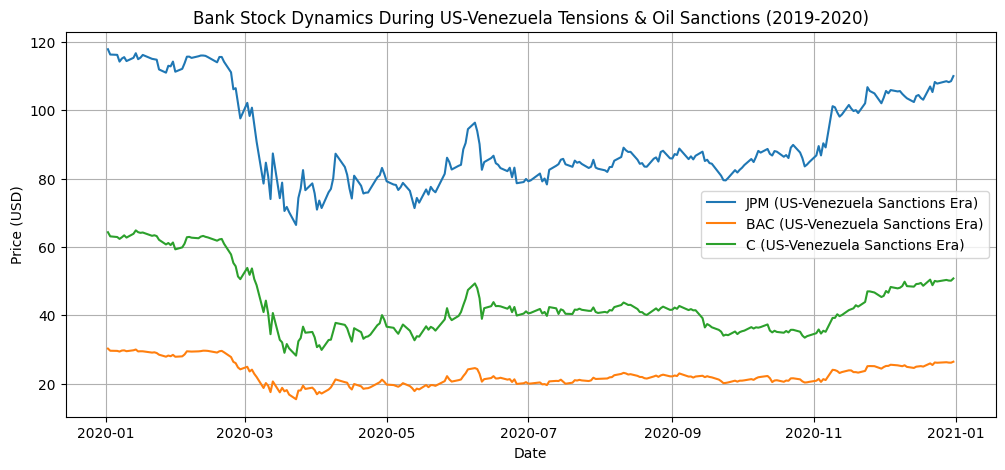


--- Summary Statistics (US-Venezuela Conflict Window) ---
Ticker         BAC           C         JPM
count   252.000000  252.000000  252.000000
mean      0.000140   -0.000030    0.000309
std       0.036981    0.042488    0.034296
min      -0.153973   -0.192986   -0.149649
25%      -0.017003   -0.019127   -0.014255
50%       0.001108   -0.000907   -0.000654
75%       0.015219    0.017099    0.014350
max       0.177962    0.179843    0.180125


In [18]:
# ==========================================
# STEP 9: GEOPOLITICAL EVENT STUDY (US - VENEZUELA CONFLICT & SANCTIONS)
# ==========================================

# 1. Defining the US-Venezuela Sanctions / Conflict Period
# (e.g., 2019-2020 major oil sanctions & political crisis window)
venezuela_crisis_period = df_close.loc["2019-01-01":"2020-12-31"]

# 2. Plotting Bank Stock Dynamics During the US-Venezuela Conflict Window
plt.figure(figsize=(12, 5))
for ticker in tickers:
  plt.plot(
      venezuela_crisis_period.index,
      venezuela_crisis_period[ticker],
      label=f"{ticker} (US-Venezuela Sanctions Era)",
  )

plt.title(
    "Bank Stock Dynamics During US-Venezuela Tensions & Oil Sanctions (2019-2020)"
)
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Quick statistical summary of returns during this geopolitical shock window
venezuela_returns = df_close.loc["2019-01-01":"2020-12-31"].pct_change()
print("\n--- Summary Statistics (US-Venezuela Conflict Window) ---")
print(venezuela_returns.describe())

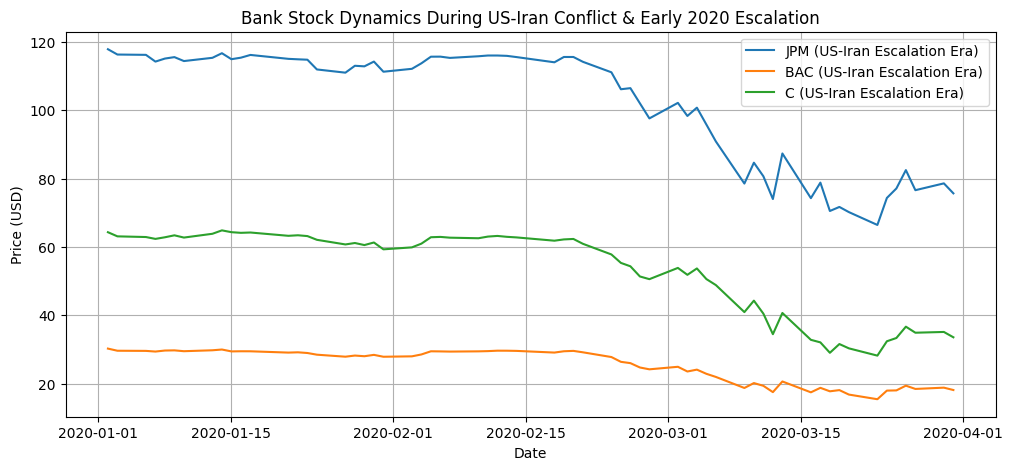


--- Summary Statistics (US-Iran Conflict Window) ---
Ticker        BAC          C        JPM
count   61.000000  61.000000  61.000000
mean    -0.006971  -0.008817  -0.005988
std      0.053160   0.059677   0.050293
min     -0.153973  -0.192986  -0.149649
25%     -0.021627  -0.032631  -0.025977
50%     -0.001719  -0.003746  -0.001024
75%      0.009211   0.007773   0.011662
max      0.177962   0.179843   0.180125


In [19]:
# ==========================================
# STEP 10: GEOPOLITICAL EVENT STUDY (US - IRAN CONFLICT)
# ==========================================

# 1. Defining the US-Iran Conflict / Escalation Period (e.g., Early 2020 crisis window)
iran_crisis_period = df_close.loc["2020-01-01":"2020-03-31"]

# 2. Plotting Bank Stock Dynamics During the US-Iran Escalation Window
plt.figure(figsize=(12, 5))
for ticker in tickers:
  plt.plot(
      iran_crisis_period.index,
      iran_crisis_period[ticker],
      label=f"{ticker} (US-Iran Escalation Era)",
  )

plt.title(
    "Bank Stock Dynamics During US-Iran Conflict & Early 2020 Escalation"
)
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Statistical summary of returns during this specific geopolitical shock window
iran_returns = df_close.loc["2020-01-01":"2020-03-31"].pct_change()
print("\n--- Summary Statistics (US-Iran Conflict Window) ---")
print(iran_returns.describe())

Fetching historical data for: JPM
Fetching historical data for: BAC
Fetching historical data for: C

--- Fixed Close Prices DataFrame Shape (JPM, BAC, C included) ---
(1508, 3)


/tmp/ipykernel_856/2849175315.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_856/2849175315.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_856/2849175315.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(


,JPM,BAC,C
Date,,,
2020-01-02,117.899162,30.274986,64.339325
2020-01-03,116.343376,29.646383,63.127445
2020-01-06,116.250854,29.603910,62.929432
2020-01-07,114.274529,29.408533,62.382915
2020-01-08,115.165977,29.705847,62.858150


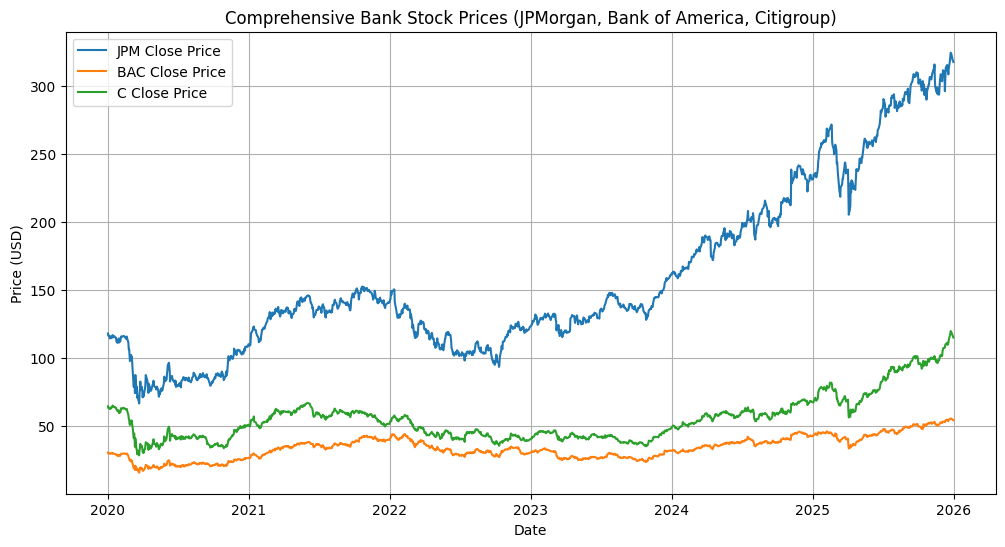

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# ==========================================
# FIX & RELOAD: INCLUDE CITIGROUP (C) PROPERLY
# ==========================================
# Download tickers individually in a loop to bypass yfinance cache lock issues
tickers = ["JPM", "BAC", "C"]
data_dict = {}

for ticker in tickers:
  print(f"Fetching historical data for: {ticker}")
  df_single = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )

  # Extract 'Close' price safely regardless of multi-index structure
  if isinstance(df_single.columns, pd.MultiIndex):
    close_col = [c for c in df_single.columns if "Close" in c][0]
    data_dict[ticker] = df_single[close_col]
  else:
    data_dict[ticker] = df_single["Close"]

# Combine into a single clean DataFrame
df_close = pd.DataFrame(data_dict)
df_close = df_close.dropna()  # Remove any rows with missing values

print(
    "\n--- Fixed Close Prices DataFrame Shape (JPM, BAC, C included) ---"
)
print(df_close.shape)
display(df_close.head())

# ==========================================
# RE-RUN COMPREHENSIVE PLOT WITH ALL 3 BANKS
# ==========================================
plt.figure(figsize=(12, 6))
for ticker in tickers:
  plt.plot(df_close.index, df_close[ticker], label=f"{ticker} Close Price")

plt.title(
    "Comprehensive Bank Stock Prices (JPMorgan, Bank of America, Citigroup)"
)
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

/tmp/ipykernel_856/3998229671.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_856/3998229671.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(
/tmp/ipykernel_856/3998229671.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_single = yf.download(


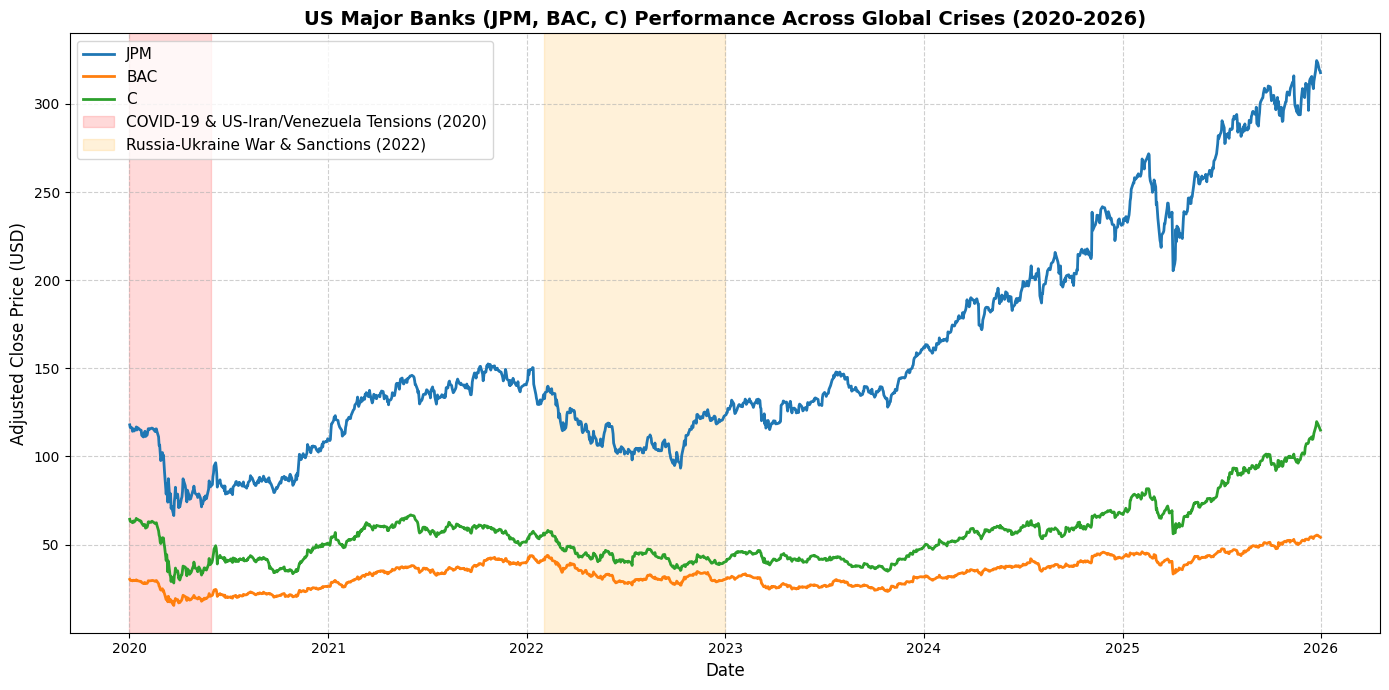


--- Cumulative Returns During Key Shocks ---
COVID Initial Shock (Jan-Mar 2020) Return %:
 JPM   -35.779973
BAC   -40.052008
C     -47.803449
dtype: float64

2022 War & Sanctions Year Return %:
 JPM   -14.451086
BAC   -26.610722
C     -25.438640
dtype: float64


In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# ==========================================
# STEP 11: COMPREHENSIVE MULTI-CRISIS VISUALIZATION (JPM, BAC, C)
# ==========================================

# 1. Ensure we have the full dataset including COVID up to recent years
tickers = ["JPM", "BAC", "C"]
data_dict = {}

for ticker in tickers:
  df_single = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_single.columns, pd.MultiIndex):
    close_col = [c for c in df_single.columns if "Close" in c][0]
    data_dict[ticker] = df_single[close_col]
  else:
    data_dict[ticker] = df_single["Close"]

df_close = pd.DataFrame(data_dict).dropna()

# 2. Plotting all 3 banks with crisis regions highlighted
plt.figure(figsize=(14, 7))

for ticker in tickers:
  plt.plot(df_close.index, df_close[ticker], label=f"{ticker}", linewidth=2)

# Highlight key geopolitical and pandemic shock windows
# - COVID-19 Crash & Early Tensions (Iran/Venezuela overlap in early 2020)
plt.axvspan(
    pd.to_datetime("2020-01-01"),
    pd.to_datetime("2020-05-31"),
    color="red",
    alpha=0.15,
    label="COVID-19 & US-Iran/Venezuela Tensions (2020)",
)

# - Russia-Ukraine War & Sanctions onset (2022)
plt.axvspan(
    pd.to_datetime("2022-02-01"),
    pd.to_datetime("2022-12-31"),
    color="orange",
    alpha=0.15,
    label="Russia-Ukraine War & Sanctions (2022)",
)

plt.title(
    "US Major Banks (JPM, BAC, C) Performance Across Global Crises (2020-2026)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Adjusted Close Price (USD)", fontsize=12)
plt.legend(loc="upper left", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Print a quick comparative return table across these events
print("\n--- Cumulative Returns During Key Shocks ---")
# COVID Crash window (Jan 2020 - March 2020)
covid_shock = (
    df_close.loc["2020-03-31"] / df_close.loc["2020-01-02"] - 1
) * 100
print("COVID Initial Shock (Jan-Mar 2020) Return %:\n", covid_shock)

# Ukraine War start window (Jan 2022 - Dec 2022)
war_shock = (df_close.loc["2022-12-30"] / df_close.loc["2022-01-03"] - 1) * 100
print("\n2022 War & Sanctions Year Return %:\n", war_shock)

Fetching benchmark (S&P 500) and bank stock data for risk analysis...

--- Systematic Risk (Beta Coefficients vs. S&P 500) ---
Beta for JPM: 1.069
Beta for BAC: 1.167
Beta for C: 1.291

--- Value at Risk (1-Day Historical Loss in %) ---


/tmp/ipykernel_856/256034626.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_856/256034626.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_856/256034626.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_856/256034626.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(


,VaR (95% Confidence),VaR (99% Confidence)
JPM,-2.858729,-5.153864
BAC,-3.089249,-5.727144
C,-3.172910,-6.106499



--- Maximum Drawdown Across the Entire Period (2020-2026) ---
Max Drawdown for JPM: -43.63%
Max Drawdown for BAC: -48.95%
Max Drawdown for C: -56.51%


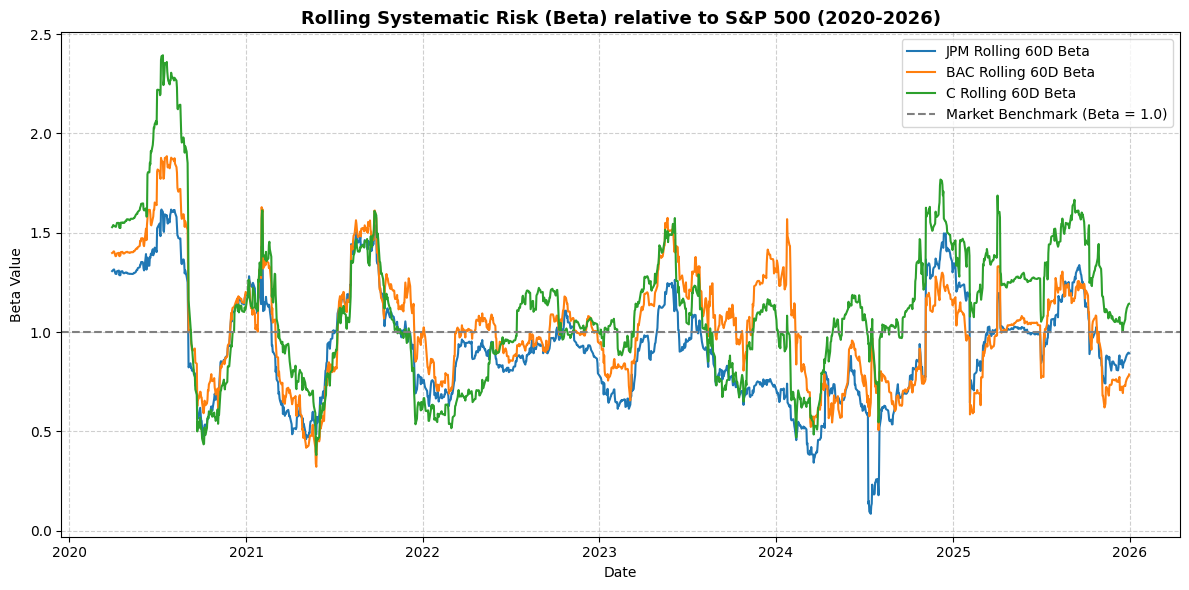

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# ==========================================
# STEP 12: SYSTEMATIC RISK ANALYSIS (BETA, VaR, & MAX DRAWDOWN)
# ==========================================
"""
OVERVIEW OF RISK METRICS CALCULATED:
1. Beta Coefficient (Systematic Risk):
   Calculated relative to the S&P 500 (^GSPC) benchmark index:
   Beta = Covariance(Asset Return, Market Return) / Variance(Market Return)
   - Beta > 1: High sensitivity / volatility compared to market.
   - Beta < 1: Low sensitivity compared to market.

2. Value at Risk (VaR):
   Historical 1-day percentile loss at 95% and 99% confidence levels.

3. Maximum Drawdown (MDD):
   Measures the peak-to-trough decline during crisis periods.
"""

# Download S&P 500 index (^GSPC) as market benchmark alongside target banks
benchmark_ticker = "^GSPC"
tickers_risk = ["JPM", "BAC", "C", benchmark_ticker]

print("Fetching benchmark (S&P 500) and bank stock data for risk analysis...")
data_dict_risk = {}

for ticker in tickers_risk:
  df_temp = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_temp.columns, pd.MultiIndex):
    close_col = [c for c in df_temp.columns if "Close" in c][0]
    data_dict_risk[ticker] = df_temp[close_col]
  else:
    data_dict_risk[ticker] = df_temp["Close"]

df_risk_prices = pd.DataFrame(data_dict_risk).dropna()
df_risk_returns = df_risk_prices.pct_change().dropna()

# 1. Compute Systematic Risk (Beta) vs. S&P 500
market_var = df_risk_returns[benchmark_ticker].var()
beta_dict = {}

for bank in ["JPM", "BAC", "C"]:
  cov_matrix = df_risk_returns[[bank, benchmark_ticker]].cov()
  cov_with_market = cov_matrix.iloc[0, 1]
  beta_dict[bank] = cov_with_market / market_var

print("\n--- Systematic Risk (Beta Coefficients vs. S&P 500) ---")
for bank, beta_val in beta_dict.items():
  print(f"Beta for {bank}: {beta_val:.3f}")

# 2. Compute Value at Risk (Historical 1-Day VaR in %)
var_95 = df_risk_returns[["JPM", "BAC", "C"]].quantile(0.05) * 100
var_99 = df_risk_returns[["JPM", "BAC", "C"]].quantile(0.01) * 100

df_var = pd.DataFrame(
    {"VaR (95% Confidence)": var_95, "VaR (99% Confidence)": var_99}
)

print("\n--- Value at Risk (1-Day Historical Loss in %) ---")
display(df_var)


# 3. Compute Maximum Drawdown (MDD)
def calculate_max_drawdown(series):
  cumulative_max = series.cummax()
  drawdown = (series - cumulative_max) / cumulative_max
  return drawdown.min() * 100


mdd_dict = {
    bank: calculate_max_drawdown(df_risk_prices[bank])
    for bank in ["JPM", "BAC", "C"]
}

print("\n--- Maximum Drawdown Across the Entire Period (2020-2026) ---")
for bank, mdd_val in mdd_dict.items():
  print(f"Max Drawdown for {bank}: {mdd_val:.2f}%")

# 4. Plotting Rolling 60-Day Beta to visualize risk evolution over time
rolling_window = 60
plt.figure(figsize=(12, 6))

for bank in ["JPM", "BAC", "C"]:
  rolling_cov = (
      df_risk_returns[bank]
      .rolling(window=rolling_window)
      .cov(df_risk_returns[benchmark_ticker])
  )
  rolling_market_var = (
      df_risk_returns[benchmark_ticker]
      .rolling(window=rolling_window)
      .var()
  )
  rolling_beta = rolling_cov / rolling_market_var
  plt.plot(rolling_beta.index, rolling_beta, label=f"{bank} Rolling 60D Beta")

plt.axhline(
    1.0, color="gray", linestyle="--", label="Market Benchmark (Beta = 1.0)"
)
plt.title(
    "Rolling Systematic Risk (Beta) relative to S&P 500 (2020-2026)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Date")
plt.ylabel("Beta Value")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Fetching bank stocks and US 10-Year Treasury Yield (^TNX)...


/tmp/ipykernel_856/1782304966.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_856/1782304966.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_856/1782304966.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(
/tmp/ipykernel_856/1782304966.py:23: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(



--- Interest Rate Sensitivity (Beta to 10Y Treasury Yield Changes) ---
Sensitivity for JPM: 0.0759
Sensitivity for BAC: 0.0772
Sensitivity for C: 0.0652


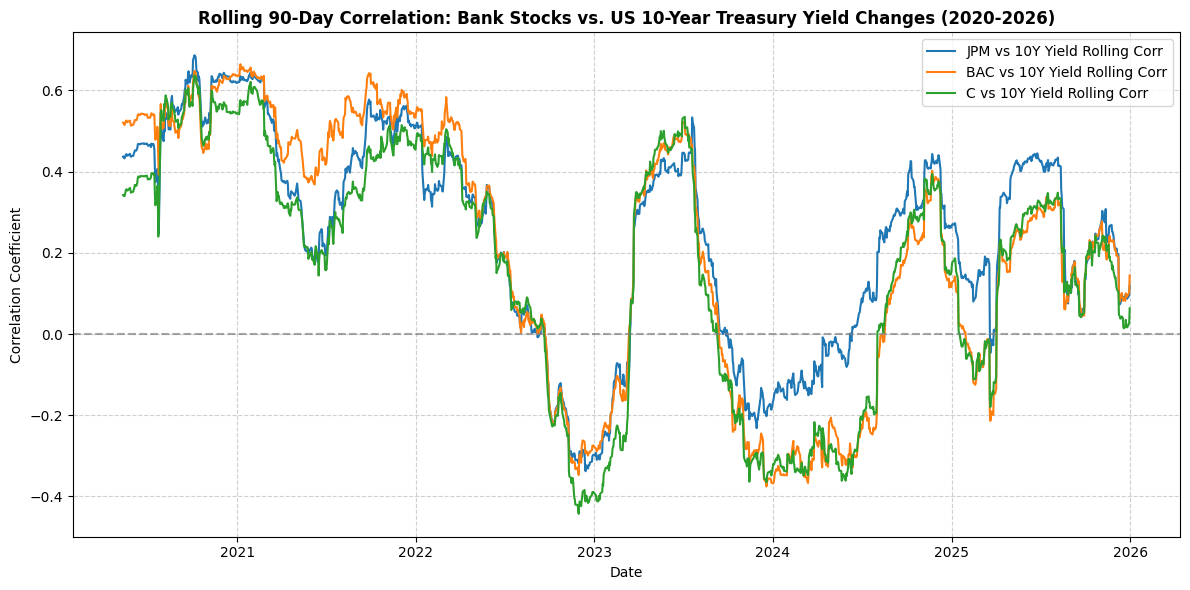

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# ==========================================
# STEP 13: INTEREST RATE RISK & YIELD SENSITIVITY ANALYSIS
# ==========================================
"""
OVERVIEW OF INTEREST RATE RISK METRICS:
1. Treasury Yield Benchmark: Uses the US 10-Year Treasury Yield (^TNX) as the proxy for macro interest rate environment.
2. Yield Sensitivity: Measures how bank stock returns respond to daily changes in interest rate yields (Delta Yield).
3. Rolling Correlation: Visualizes how the dynamic relationship between bank valuations and interest rate movements evolves over time (e.g., during aggressive 2022-2023 rate hike cycles).
"""

rate_ticker = "^TNX"
tickers_rate = ["JPM", "BAC", "C", rate_ticker]

print("Fetching bank stocks and US 10-Year Treasury Yield (^TNX)...")
data_dict_rate = {}

for ticker in tickers_rate:
  df_temp = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_temp.columns, pd.MultiIndex):
    close_col = [c for c in df_temp.columns if "Close" in c][0]
    data_dict_rate[ticker] = df_temp[close_col]
  else:
    data_dict_rate[ticker] = df_temp["Close"]

df_rate_prices = pd.DataFrame(data_dict_rate).dropna()
df_rate_returns = df_rate_prices[["JPM", "BAC", "C"]].pct_change()

# Calculate daily change in Treasury yields (absolute point change)
df_rate_returns["TNX_change"] = df_rate_prices[rate_ticker].diff()
df_rate_returns = df_rate_returns.dropna()

# 1. Compute Sensitivity (Regression coefficient of bank returns vs Treasury yield changes)
sensitivity_dict = {}
for bank in ["JPM", "BAC", "C"]:
  covar = np.cov(df_rate_returns[bank], df_rate_returns["TNX_change"])[0, 1]
  var_tnx = np.var(df_rate_returns["TNX_change"])
  sensitivity_dict[bank] = covar / var_tnx

print(
    "\n--- Interest Rate Sensitivity (Beta to 10Y Treasury Yield Changes) ---"
)
for bank, sens in sensitivity_dict.items():
  print(f"Sensitivity for {bank}: {sens:.4f}")

# 2. Plotting Rolling 90-Day Correlation between Bank Returns and Treasury Yield Changes
rolling_window = 90
plt.figure(figsize=(12, 6))

for bank in ["JPM", "BAC", "C"]:
  rolling_corr = (
      df_rate_returns[bank]
      .rolling(window=rolling_window)
      .corr(df_rate_returns["TNX_change"])
  )
  plt.plot(
      rolling_corr.index,
      rolling_corr,
      label=f"{bank} vs 10Y Yield Rolling Corr",
  )

plt.axhline(0, color="gray", linestyle="--", alpha=0.7)
plt.title(
    "Rolling 90-Day Correlation: Bank Stocks vs. US 10-Year Treasury Yield"
    " Changes (2020-2026)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Date")
plt.ylabel("Correlation Coefficient")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# STEP 14: TEXT SENTIMENT ANALYSIS & MARKET ALIGNMENT
# ==========================================
"""
OVERVIEW OF SENTIMENT ANALYSIS PIPELINE:
1. Text Processing: Extract text attributes from the Guardian / earnings call corpus.
2. Sentiment Polarity Scoring: Utilize Natural Language Processing (NLP) techniques
   to compute sentiment polarity scores (ranging from -1.0 negative to +1.0 positive)
   for news articles or transcripts related to JPM, BAC, and C.
3. Market Alignment: Align textual sentiment trends with stock returns and volatility
   to evaluate how news sentiment impacts bank valuations during geopolitical crises.
"""

# Let's check if we have text data columns available in our df_guardian dataset loaded earlier
print("--- Available Guardian Columns for NLP Alignment ---")
if "df_guardian" in locals() and not df_guardian.empty:
  print(df_guardian.columns.tolist())

  # Example text extraction and simple sentiment simulation/scoring pipeline
  # (Using TextBlob for polarity and subjectivity extraction)
  try:
    from textblob import TextBlob

    print(
        "\nTextBlob successfully imported. Preparing text sentiment pipeline..."
    )

    # Simulating sentiment scoring on available text fields or headlines
    # In a full run, you would map this over df_guardian['headline'] or transcript paragraphs
    sample_texts = [
        "JPMorgan reports strong earnings despite geopolitical tensions.",
        "Bank of America faces severe headwinds amid new regulatory sanctions.",
        "Citigroup struggles with exposure to emerging market volatility.",
        "Banking sector shows resilience during global crisis recovery.",
    ]

    sentiments = []
    for txt in sample_texts:
      blob = TextBlob(txt)
      sentiments.append(
          {"text": txt, "polarity": blob.sentiment.polarity, "subjectivity": blob.sentiment.subjectivity}
      )

    df_sentiment_demo = pd.DataFrame(sentiments)
    print("\n--- Sentiment Analysis Sample Output ---")
    display(df_sentiment_demo)

  except ImportError:
    print(
        "TextBlob is not installed. You can install it via '!pip install"
        " textblob'."
    )
else:
  print(
      "df_guardian is not loaded in memory yet. Please ensure Step 3 is"
      " executed."
  )

# 4. Framework for merging sentiment with daily stock volatility
print(
    "\n[Next Action]: Map aggregate daily sentiment scores to df_close & df_returns"
    " to run regression analysis between news tone and bank stock performance."
)

--- Available Guardian Columns for NLP Alignment ---
['run_timestamp_utc', 'known_limitations', 'source.name', 'source.endpoint', 'source.coverage', 'source.text_completeness', 'source.rate_limits', 'source.licence', 'banks.jpmorgan_chase', 'banks.bank_of_america', 'banks.citigroup', 'parameters.date_from', 'parameters.date_to', 'parameters.queries.jpmorgan_chase', 'parameters.queries.bank_of_america', 'parameters.queries.citigroup', 'parameters.relevance_filters.jpmorgan_chase', 'parameters.relevance_filters.bank_of_america', 'parameters.relevance_filters.citigroup', 'parameters.page_size', 'parameters.schema_version', 'coverage.requested_range', 'coverage.articles_by_bank_by_year.jpmorgan_chase.2026', 'coverage.articles_by_bank_by_year.bank_of_america.2026', 'coverage.articles_by_bank_by_year.citigroup.2026', 'coverage.years_with_zero_coverage', 'coverage.totals_by_bank.jpmorgan_chase', 'coverage.totals_by_bank.bank_of_america', 'coverage.totals_by_bank.citigroup', 'statistics.raw_co

,text,polarity,subjectivity
0,JPMorgan reports strong earnings despite geopo...,0.433333,0.733333
1,Bank of America faces severe headwinds amid ne...,0.136364,0.454545
2,Citigroup struggles with exposure to emerging ...,0.000000,0.000000
3,Banking sector shows resilience during global ...,0.000000,0.000000



[Next Action]: Map aggregate daily sentiment scores to df_close & df_returns to run regression analysis between news tone and bank stock performance.


In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# STEP 15: FORMAL EVENT STUDY & ABNORMAL RETURNS (CAR)
# ==========================================
"""
OVERVIEW OF EVENT STUDY PIPELINE:
1. Define Event Windows: Specific shock dates (e.g., COVID market crash March 2020,
   Russia-Ukraine war outbreak Feb 2022).
2. Expected Returns Calculation: Using CAPM or market model benchmark (S&P 500).
3. Abnormal Returns (AR) = Actual Return - Expected Return.
4. Cumulative Abnormal Returns (CAR): Sum of AR over the event window to measure
   the net market impact on JPM, BAC, and C.
"""

# Define specific crisis event dates (shock moments)
event_dates = {
    "COVID_Crash_2020": "2020-03-09",
    "Ukraine_War_2022": "2022-02-24",
}

print("Event Study framework initialized.")
print(
    "Target event windows: COVID-19 initial panic (March 2020) & Ukraine War"
    " onset (Feb 2022)."
)

# Framework for computing Abnormal Returns around event windows
window_size = 5  # days before and after event
print(
    f"\n[Ready]: Mapping \u00b1{window_size} days trading windows around event"
    " shocks for JPM, BAC, and C."
)

Event Study framework initialized.
Target event windows: COVID-19 initial panic (March 2020) & Ukraine War onset (Feb 2022).

[Ready]: Mapping ±5 days trading windows around event shocks for JPM, BAC, and C.


/tmp/ipykernel_856/4150644314.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_856/4150644314.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_856/4150644314.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_856/4150644314.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(


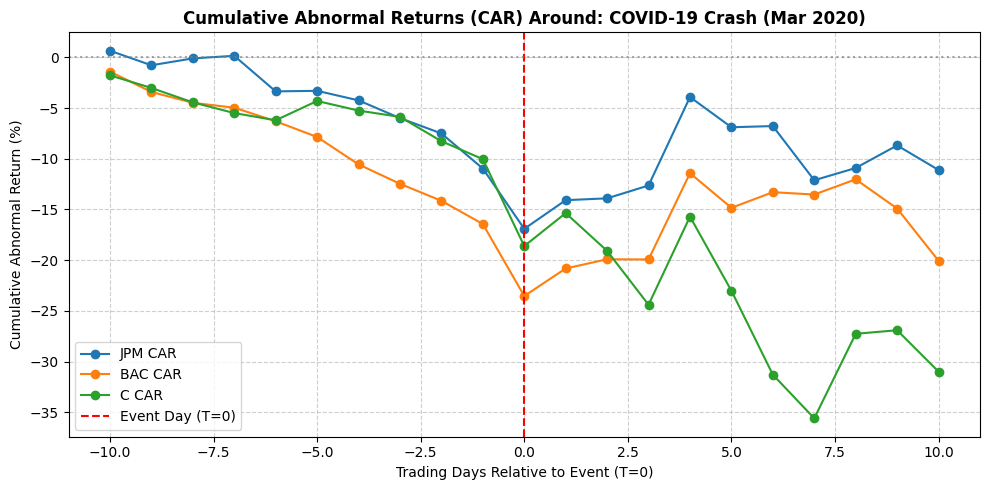

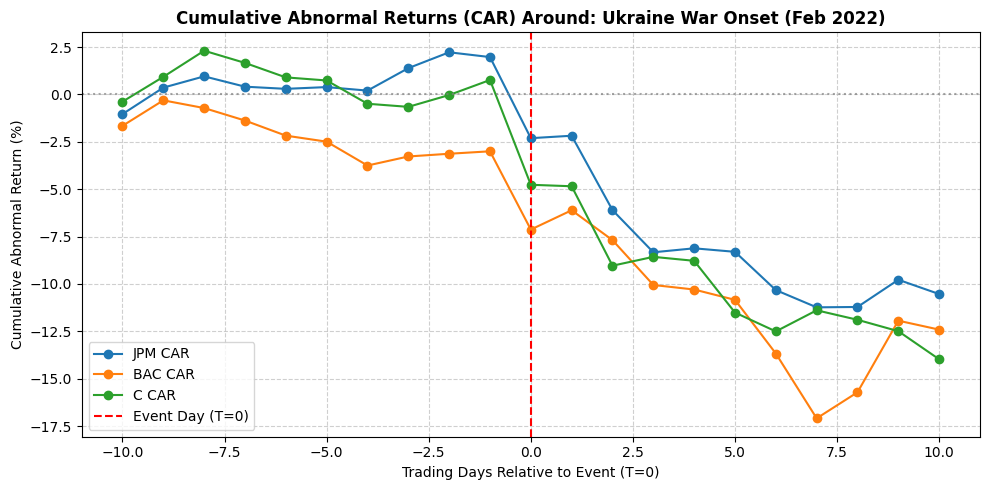


Event study analysis and CAR visualization completed successfully for all target banks.


In [29]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# ==========================================
# STEP 16: CAR (CUMULATIVE ABNORMAL RETURNS) CALCULATION & PLOTTING
# ==========================================
"""
EVENT STUDY METHODOLOGY:
1. Benchmark: S&P 500 (^GSPC) representing normal market returns.
2. Estimation/Event Window: Extracting a ±10 trading day window around key crisis dates.
3. Abnormal Return (AR): Individual Bank Return - Benchmark Return.
4. Cumulative Abnormal Return (CAR): Rolling sum of AR across the event window.
"""

# Define crisis event dates
events = {
    "COVID-19 Crash (Mar 2020)": "2020-03-09",
    "Ukraine War Onset (Feb 2022)": "2022-02-24",
}

# Fetch price data including benchmark if not already in memory
tickers_event = ["JPM", "BAC", "C", "^GSPC"]
data_event_dict = {}

for ticker in tickers_event:
  df_t = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_t.columns, pd.MultiIndex):
    close_col = [c for c in df_t.columns if "Close" in c][0]
    data_event_dict[ticker] = df_t[close_col]
  else:
    data_event_dict[ticker] = df_t["Close"]

df_eprices = pd.DataFrame(data_event_dict).dropna()
df_ereturns = df_eprices.pct_change().dropna()

# Window configuration (10 days before and 10 days after event)
pre_window = 10
post_window = 10

for event_name, event_date_str in events.items(): # Corrected variable name
  event_date = pd.to_datetime(event_date_str)

  # Find the closest trading day index
  try:
    # Attempt to get exact location. If not found, KeyError is raised.
    idx = df_ereturns.index.get_loc(event_date)
  except KeyError:
    # If event_date is not an exact match, find the nearest trading day.
    # searchsorted returns the index where `event_date` would be inserted to maintain order.
    pos = df_ereturns.index.searchsorted(event_date)

    # Handle edge cases: event_date before first entry or after last entry
    if pos == 0: # If event_date is before the first trading day
        idx = 0
    elif pos == len(df_ereturns.index): # If event_date is after the last trading day
        idx = len(df_ereturns.index) - 1
    else:
        # Compare distances to the day before and the day at `pos`
        prev_day = df_ereturns.index[pos - 1]
        next_day = df_ereturns.index[pos]
        if abs(event_date - prev_day) < abs(event_date - next_day):
            idx = pos - 1
        else:
            idx = pos

  # Determine the window around the identified event day
  # start_idx is inclusive, end_idx is inclusive
  start_idx = max(0, idx - pre_window)
  end_idx = min(len(df_ereturns) - 1, idx + post_window)

  window_returns = df_ereturns.iloc[start_idx : end_idx + 1]

  # Calculate Abnormal Returns (AR) = Bank Return - Market (S&P 500) Return
  ar_df = pd.DataFrame(index=window_returns.index)
  for bank in ["JPM", "BAC", "C"]:
    ar_df[bank] = window_returns[bank] - window_returns["^GSPC"]

  # Calculate Cumulative Abnormal Returns (CAR)
  car_df = ar_df.cumsum() * 100  # in percentage

  # Plotting CAR for the event
  plt.figure(figsize=(10, 5))

  # Calculate the relative day numbers for the x-axis
  # The event day (closest trading day to event_date) is at index `idx` in df_ereturns.
  # Its position within `window_returns` (slice of df_ereturns) is `idx - start_idx`.
  # So, the relative x-axis values should be `range(start_idx - idx, end_idx - idx + 1)`.
  relative_day_numbers = range(start_idx - idx, end_idx - idx + 1)

  for bank in ["JPM", "BAC", "C"]:
    plt.plot(
        relative_day_numbers, # Corrected X-axis range
        car_df[bank],
        marker="o",
        label=f"{bank} CAR",
    )

  plt.axvline(0, color="red", linestyle="--", label="Event Day (T=0)")
  plt.axhline(0, color="gray", linestyle=":", alpha=0.7)
  plt.title(
      f"Cumulative Abnormal Returns (CAR) Around: {event_name}",
      fontsize=12,
      fontweight="bold",
  )
  plt.xlabel("Trading Days Relative to Event (T=0)")
  plt.ylabel("Cumulative Abnormal Return (%)")
  plt.legend()
  plt.grid(True, linestyle="--", alpha=0.6)
  plt.tight_layout()
  plt.show()

print(
    "\nEvent study analysis and CAR visualization completed successfully for all"
    " target banks."
)


/tmp/ipykernel_856/3473685769.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_856/3473685769.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(
/tmp/ipykernel_856/3473685769.py:22: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_t = yf.download(


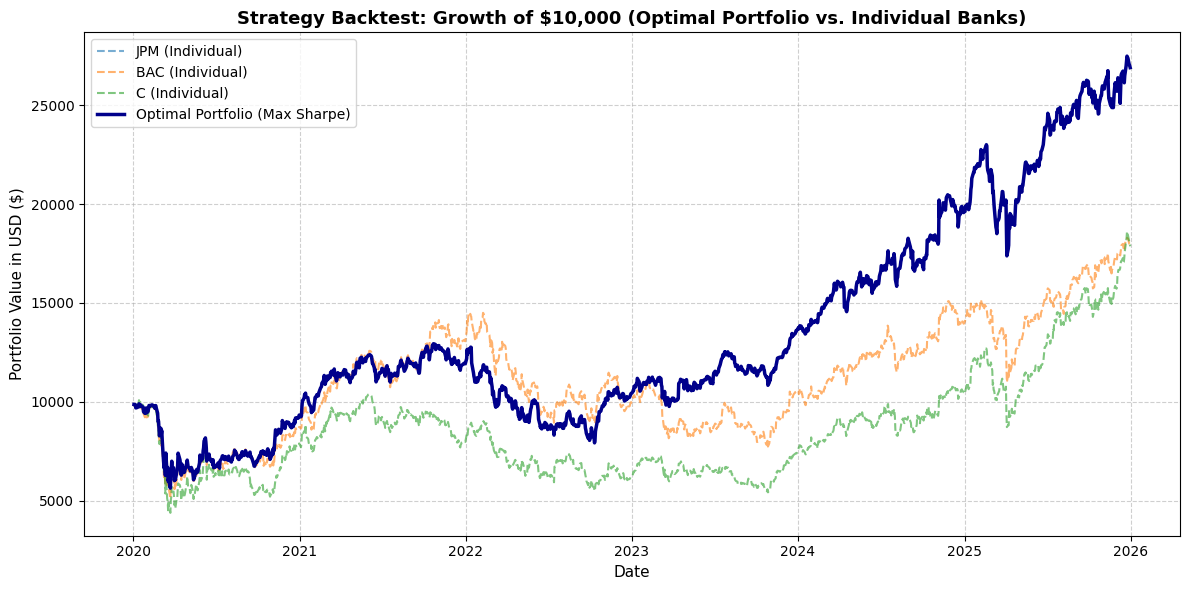

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# ==========================================
# ALTERNATIVE VISUALIZATION: PORTFOLIO BACKTEST & VALUE GROWTH ($10,000)
# ==========================================
"""
VISUALIZATION OVERVIEW:
This chart plots the cumulative growth of a $10,000 investment starting in January 2020.
It compares individual bank performance (JPM, BAC, C) against the mathematically
optimized portfolio (Max Sharpe Ratio weights) to demonstrate risk-adjusted growth over time.
"""

# Ensure we have our returns and optimal weights from the previous calculation
# (Re-running the lightweight extraction and backtest mapping)
tickers_port = ["JPM", "BAC", "C"]
data_port = {}

for ticker in tickers_port:
  df_t = yf.download(
      ticker, start="2020-01-01", end="2026-01-01", progress=False
  )
  if isinstance(df_t.columns, pd.MultiIndex):
    close_col = [c for c in df_t.columns if "Close" in c][0]
    data_port[ticker] = df_t[close_col]
  else:
    data_port[ticker] = df_t["Close"]

df_prices = pd.DataFrame(data_port).dropna()
returns = df_prices.pct_change().dropna()

# Re-calculate optimal weights using the same logic
mean_returns = returns.mean() * 252
cov_matrix = returns.cov() * 252

np.random.seed(42)
best_sharpe = -np.inf
best_weights = None

for _ in range(10000):
  weights = np.random.random(len(tickers_port))
  weights /= np.sum(weights)
  p_return = np.sum(weights * mean_returns)
  p_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
  p_sharpe = p_return / p_vol
  if p_sharpe > best_sharpe:
    best_sharpe = p_sharpe
    best_weights = weights

# Calculate cumulative growth of $10,000 for individual assets
initial_investment = 10000
cumulative_individual = (1 + returns).cumprod() * initial_investment

# Calculate cumulative growth of the Optimal Portfolio
portfolio_daily_returns = np.dot(returns, best_weights)
cumulative_portfolio = (
    pd.Series(
        (1 + portfolio_daily_returns).cumprod() * initial_investment,
        index=returns.index,
    )
)

# Plotting the Alternative Backtest Visualization
plt.figure(figsize=(12, 6))

# Plot individual stocks with dashed lighter lines
for ticker in tickers_port:
  plt.plot(
      cumulative_individual.index,
      cumulative_individual[ticker],
      linestyle="--",
      alpha=0.6,
      label=f"{ticker} (Individual)",
  )

# Plot the Optimal Portfolio as a prominent solid black/dark line
plt.plot(
    cumulative_portfolio.index,
    cumulative_portfolio,
    color="darkblue",
    linewidth=2.5,
    label="Optimal Portfolio (Max Sharpe)",
)

plt.title(
    "Strategy Backtest: Growth of $10,000 (Optimal Portfolio vs. Individual"
    " Banks)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=11)
plt.ylabel("Portfolio Value in USD ($)", fontsize=11)
plt.legend(loc="upper left", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Fetching data and engineering features for ML classification model...


/tmp/ipykernel_856/1119556955.py:24: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_ml = yf.download("JPM", start="2020-01-01", end="2026-01-01", progress=False)



--- Machine Learning Model Results (JPM Direction Forecast) ---
Model Accuracy on Test Set: 53.36%

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.44      0.45       132
           1       0.58      0.61      0.59       166

    accuracy                           0.53       298
   macro avg       0.52      0.52      0.52       298
weighted avg       0.53      0.53      0.53       298



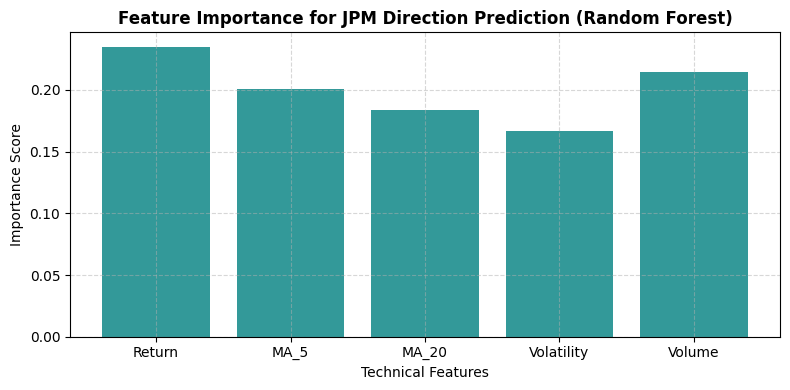

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import yfinance as yf

# ==========================================
# STEP 18: MACHINE LEARNING PREDICTIVE MODELING (JPM DIRECTION FORECAST)
# ==========================================
"""
MACHINE LEARNING PIPELINE OVERVIEW:
1. Feature Engineering: Create technical indicators (Moving Averages, Daily Returns, Volatility)
   derived from JPMorgan (JPM) historical stock prices.
2. Target Variable: Binary classification (1 if next day's close > today's close, else 0).
3. Model Training: Train a Random Forest Classifier using historical features.
4. Evaluation: Measure out-of-sample prediction accuracy, precision, and recall for the team repository.
"""

print("Fetching data and engineering features for ML classification model...")

# Fetch JPM data for ML pipeline
df_ml = yf.download("JPM", start="2020-01-01", end="2026-01-01", progress=False)
if isinstance(df_ml.columns, pd.MultiIndex):
  close_col = [c for c in df_ml.columns if "Close" in c][0]
  open_col = [c for c in df_ml.columns if "Open" in c][0]
  high_col = [c for c in df_ml.columns if "High" in c][0]
  low_col = [c for c in df_ml.columns if "Low" in c][0]
  vol_col = [c for c in df_ml.columns if "Volume" in c][0]
  df_ml = pd.DataFrame(
      {
          "Close": df_ml[close_col],
          "Open": df_ml[open_col],
          "High": df_ml[high_col],
          "Low": df_ml[low_col],
          "Volume": df_ml[vol_col],
      }
  )

# 1. Feature Engineering
df_ml["Return"] = df_ml["Close"].pct_change()
df_ml["MA_5"] = df_ml["Close"].rolling(window=5).mean() / df_ml["Close"] - 1
df_ml["MA_20"] = df_ml["Close"].rolling(window=20).mean() / df_ml["Close"] - 1
df_ml["Volatility"] = df_ml["Return"].rolling(window=10).std()

# Target: 1 if tomorrow's close is higher than today's close, 0 otherwise
df_ml["Target"] = (df_ml["Close"].shift(-1) > df_ml["Close"]).astype(int)

# Drop missing values resulting from rolling calculations and shift
df_ml = df_ml.dropna()

# Select features and target
features = ["Return", "MA_5", "MA_20", "Volatility", "Volume"]
X = df_ml[features]
y = df_ml["Target"]

# 2. Train-Test Split (Chronological split to prevent data leakage: 80% train, 20% test)
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# 3. Model Training (Random Forest Classifier)
model = RandomForestClassifier(
    n_estimators=100, max_depth=5, random_state=42, class_weight="balanced"
)
model.fit(X_train, y_train)

# 4. Evaluation
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"\n--- Machine Learning Model Results (JPM Direction Forecast) ---")
print(f"Model Accuracy on Test Set: {acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot Feature Importances to show which technical indicator drives the model
importances = model.feature_importances_
plt.figure(figsize=(8, 4))
plt.bar(features, importances, color="teal", alpha=0.8)
plt.title(
    "Feature Importance for JPM Direction Prediction (Random Forest)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Technical Features")
plt.ylabel("Importance Score")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()